# Installing some packages


In [7]:
%pip install tensorflow matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.


In [81]:
# Load the dataset
import tensorflow as tf
import os

batch_size = 32
img_height = 180
img_width = 180

data_dir = "dataset"

In [83]:
# Load training, validation, and test datasets
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(data_dir, "train"),
    image_size=(img_height, img_width),
    batch_size=batch_size
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(data_dir, "val"),
    image_size=(img_height, img_width),
    batch_size=batch_size
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(data_dir, "test"),
    image_size=(img_height, img_width),
    batch_size=batch_size
)


Found 2567 files belonging to 5 classes.
Found 547 files belonging to 5 classes.
Found 561 files belonging to 5 classes.


In [85]:
# Get class names
class_names = train_ds.class_names
print("Classes:", class_names)

Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [87]:
# Normalize pixel values (0–255 → 0–1)
normalization_layer = tf.keras.layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y))

In [89]:
# Improve performance (cache, prefetch)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [91]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),  
    tf.keras.layers.RandomZoom(0.1),    
])

In [21]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(img_height, img_width, 3)),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(128, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(len(class_names), activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [10]:
# Train model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 203ms/step - accuracy: 0.2674 - loss: 2.1277 - val_accuracy: 0.5174 - val_loss: 1.1704
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 196ms/step - accuracy: 0.5442 - loss: 1.1070 - val_accuracy: 0.5320 - val_loss: 1.1023
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 203ms/step - accuracy: 0.6464 - loss: 0.9238 - val_accuracy: 0.6216 - val_loss: 0.9691
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 204ms/step - accuracy: 0.7504 - loss: 0.6757 - val_accuracy: 0.6325 - val_loss: 0.9909
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 195ms/step - accuracy: 0.8353 - loss: 0.4720 - val_accuracy: 0.6435 - val_loss: 1.0385
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 196ms/step - accuracy: 0.8957 - loss: 0.3169 - val_accuracy: 0.5850 - val_loss: 1.4524
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 194ms/step - accuracy: 0.9501 - loss: 0.1649 - val_accuracy: 0.6143 - val_loss: 1.4662
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 197ms/step - accuracy: 0.9717 - loss: 0.1056 - val_accu

In [11]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.05),
])

In [12]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(img_height, img_width, 3)),
    data_augmentation,  # ✅ Apply augmentations
    tf.keras.layers.Rescaling(1./255),  # Normalize images
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(128, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    #tf.keras.layers.Dropout(0.3),  # Optional: helps reduce overfitting
    tf.keras.layers.Dense(len(class_names), activation='softmax')
])


In [13]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [14]:
# Train model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

Epoch 1/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 33s 382ms/step - accuracy: 0.2280 - loss: 1.6051 - val_accuracy: 0.2450 - val_loss: 1.6003
Epoch 2/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 31s 380ms/step - accuracy: 0.2280 - loss: 1.6076 - val_accuracy: 0.2450 - val_loss: 1.6010
Epoch 3/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 31s 386ms/step - accuracy: 0.2352 - loss: 1.6064 - val_accuracy: 0.2450 - val_loss: 1.6003
Epoch 4/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 32s 394ms/step - accuracy: 0.2483 - loss: 1.6020 - val_accuracy: 0.2450 - val_loss: 1.6002
Epoch 5/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 32s 399ms/step - accuracy: 0.2413 - loss: 1.6029 - val_accuracy: 0.2450 - val_loss: 1.6005
Epoch 6/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 33s 405ms/step - accuracy: 0.2349 - loss: 1.6058 - val_accuracy: 0.2450 - val_loss: 1.6027
Epoch 7/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 33s 409ms/step - accuracy: 0.2323 - loss: 1.6063 - val_accuracy: 0.2450 - val_loss: 1.6002
Epoch 8/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 35s 438ms/step - accuracy: 0.2463 - loss: 1.6001 - val_accu

In [15]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(img_height, img_width, 3)),
    data_augmentation,
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.BatchNormalization(), # <--- Add this
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Conv2D(64, 3, activation='relu'),
    tf.keras.layers.BatchNormalization(), # <--- Add this
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Conv2D(128, 3, activation='relu'),
    tf.keras.layers.BatchNormalization(), # <--- Add this
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.BatchNormalization(), # <--- Add this
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(len(class_names), activation='softmax')
])
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)            │ (None, 180, 180, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling_2 (Rescaling)              │ (None, 180, 180, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 178, 178, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 178, 178, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 89, 89, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 89, 89, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 87, 87, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 87, 87, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 43, 43, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 43, 43, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 41, 41, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 41, 41, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 20, 20, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 20, 20, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 51200)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │       6,553,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴──────────────

 Total params: 6,649,029 (25.36 MB)

 Trainable params: 6,648,325 (25.36 MB)

 Non-trainable params: 704 (2.75 KB)

In [16]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [17]:
# Train model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 99s 1s/step - accuracy: 0.3758 - loss: 2.0355 - val_accuracy: 0.2450 - val_loss: 6.2353
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 99s 1s/step - accuracy: 0.4729 - loss: 1.4157 - val_accuracy: 0.2450 - val_loss: 14.0388
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 87s 1s/step - accuracy: 0.4920 - loss: 1.3454 - val_accuracy: 0.2450 - val_loss: 19.7085
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step - accuracy: 0.4754 - loss: 1.3546 - val_accuracy: 0.1901 - val_loss: 47.2375
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 92s 1s/step - accuracy: 0.5404 - loss: 1.1852 - val_accuracy: 0.1901 - val_loss: 86.9991
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 95s 1s/step - accuracy: 0.5123 - loss: 1.2516 - val_accuracy: 0.2358 - val_loss: 7.9213
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 98s 1s/step - accuracy: 0.5602 - loss: 1.1315 - val_accuracy: 0.2797 - val_loss: 5.5898
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step - accuracy: 0.5789 - loss: 1.0746 - val_accuracy: 0.3656 - val_l

In [30]:
# 1️⃣ Load datasets first
train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(data_dir, "train"),
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

val_ds = tf.keras.utils.image_dataset_from_directory(
      os.path.join(data_dir, "val"),
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

# 2️⃣ ✅ Extract class names BEFORE applying cache/prefetch
class_names = train_ds.class_names
num_classes = len(class_names)
print(f"Detected {num_classes} classes: {class_names}")

# 3️⃣ THEN optimize datasets with cache/prefetch
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)


Found 2567 files belonging to 5 classes.
Using 2054 files for training.
Found 547 files belonging to 5 classes.
Using 109 files for validation.
Detected 5 classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [60]:
# 2️⃣ ✅ Extract class names *before* transforming the datasets
class_names = train_ds.class_names
num_classes = len(class_names)
print(f"Detected {num_classes} classes: {class_names}")

# 3️⃣ Then apply caching & prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)


Detected 5 classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_8 (Sequential)            │ (None, 180, 180, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling_6 (Rescaling)              │ (None, 180, 180, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_11 (Conv2D)                   │ (None, 178, 178, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_8                │ (None, 178, 178, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_12 (MaxPooling2D)      │ (None, 89, 89, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 89, 89, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_12 (Conv2D)                   │ (None, 87, 87, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_9                │ (None, 87, 87, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_13 (MaxPooling2D)      │ (None, 43, 43, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 43, 43, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_13 (Conv2D)                   │ (None, 41, 41, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_10               │ (None, 41, 41, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_14 (MaxPooling2D)      │ (None, 20, 20, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 20, 20, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_4 (Flatten)                  │ (None, 51200)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 128)                 │       6,553,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_11               │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_11 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴──────────────

 Total params: 6,649,029 (25.36 MB)

 Trainable params: 6,648,325 (25.36 MB)

 Non-trainable params: 704 (2.75 KB)


Starting model training...
Epoch 1/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step - accuracy: 0.3822 - loss: 1.9683 - val_accuracy: 0.2834 - val_loss: 9.9424 - learning_rate: 0.0010
Epoch 2/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 88s 1s/step - accuracy: 0.4966 - loss: 1.3790 - val_accuracy: 0.1920 - val_loss: 4.3396 - learning_rate: 0.0010
Epoch 3/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 88s 1s/step - accuracy: 0.5197 - loss: 1.2568 - val_accuracy: 0.3272 - val_loss: 2.7680 - learning_rate: 0.0010
Epoch 4/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 87s 1s/step - accuracy: 0.5634 - loss: 1.1417 - val_accuracy: 0.3912 - val_loss: 2.0219 - learning_rate: 0.0010
Epoch 5/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step - accuracy: 0.5684 - loss: 1.0692 - val_accuracy: 0.4186 - val_loss: 2.0088 - learning_rate: 0.0010
Epoch 6/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 91s 1s/step - accuracy: 0.6132 - loss: 0.9805 - val_accuracy: 0.4680 - val_loss: 1.5274 - learning_rate: 0.0010
Epoch 7/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 93s 1s/step - accuracy: 0.6058 - l

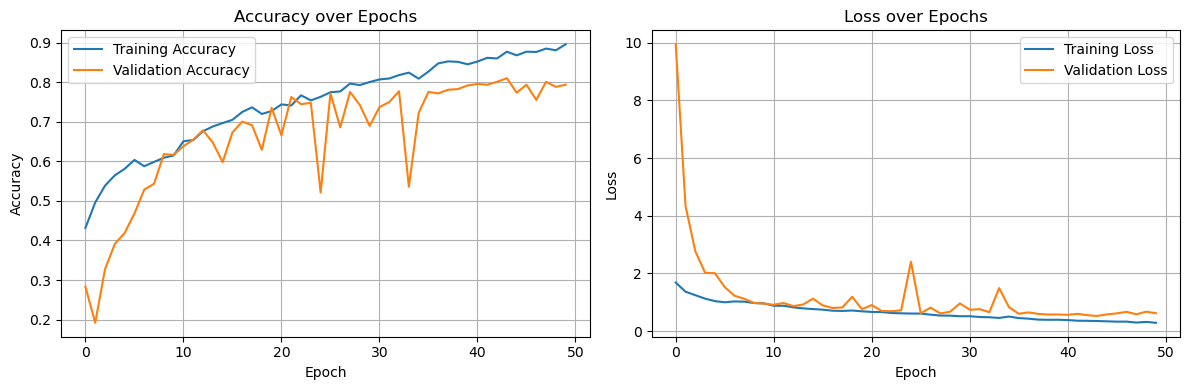

In [64]:



# --- 2. Data Augmentation Layer ---
# This layer will be part of the model to apply augmentations on the fly during training.
# This helps the model generalize better by seeing varied versions of the training images.
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),        # Randomly flip images horizontally
    tf.keras.layers.RandomRotation(0.1),             # Randomly rotate images by up to 10%
    tf.keras.layers.RandomZoom(0.2),                 # Randomly zoom in/out by up to 20%
    tf.keras.layers.RandomContrast(0.2),             # Randomly adjust contrast
    # tf.keras.layers.RandomTranslation(height_factor=0.1, width_factor=0.1), # Optional: Randomly shift images
])



# --- 4. Define the Model Architecture (with Overfitting Mitigations) ---

model = tf.keras.Sequential([
    tf.keras.Input(shape=(img_height, img_width, 3)),
    data_augmentation,          # ✅ Apply augmentations as the first layer
    tf.keras.layers.Rescaling(1./255), # Normalize pixel values to [0, 1]

    # First Convolutional Block
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.BatchNormalization(), # Stabilizes and regularizes
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.2),       # Dropout after pooling

    # Second Convolutional Block
    tf.keras.layers.Conv2D(64, 3, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.3),

    # Third Convolutional Block
    tf.keras.layers.Conv2D(128, 3, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Flatten(), # Flatten for the dense layers

    # Dense Layers
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.BatchNormalization(), # Batch norm before final dropout
    tf.keras.layers.Dropout(0.5),       # Higher dropout for dense layers

    tf.keras.layers.Dense(num_classes, activation='softmax') # Output layer
])

# Display model summary
model.summary()

# --- 5. Compile the Model ---

# Using Adam optimizer with a default learning rate.
# You can try adjusting the learning_rate if needed (e.g., 0.0005, 0.0001).
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(), # Use for integer labels
    metrics=['accuracy']
)

# --- 6. Callbacks for Training ---
# EarlyStopping: Stops training when validation loss stops improving.
# ReduceLROnPlateau: Reduces learning rate if validation loss plateaus.
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',     # Metric to monitor
        patience=15,            # Number of epochs with no improvement to wait
        restore_best_weights=True, # Restores model weights from the epoch with the best value
        verbose=1               # Print message when stopping
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',     # Metric to monitor
        factor=0.5,             # Factor by which the learning rate will be reduced. new_lr = old_lr * factor
        patience=5,             # Number of epochs with no improvement after which learning rate will be reduced
        min_lr=0.00001,         # Lower bound on the learning rate
        verbose=1               # Print message when reducing LR
    )
    # tf.keras.callbacks.TensorBoard(log_dir="logs"), # Optional: For visualization with TensorBoard
]


# --- 7. Train the Model ---

# Set a high number of epochs; EarlyStopping will determine the actual number.
epochs = 50

print("\nStarting model training...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    callbacks=callbacks
)

print("\nTraining complete.")

# --- 8. Evaluate the Model (Optional) ---
# You can further evaluate on the validation set or a separate test set if you have one.
print("\nEvaluating model on validation set:")
val_loss, val_accuracy = model.evaluate(val_ds)
print(f"Final Validation Loss: {val_loss:.4f}")
print(f"Final Validation Accuracy: {val_accuracy:.4f}")

# --- 9. Plotting Training History (Optional) ---
import matplotlib.pyplot as plt

def plot_history(history):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Accuracy over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_history(history)

# --- 10. Save the Model (Optional) ---
# model.save('my_overfitting_fixed_cnn_model.keras')
# print("\nModel saved to 'my_overfitting_fixed_cnn_model.keras'")

In [99]:
# Build the model
model.save("model.keras")

In [135]:
!pip install pillow


In [143]:

from PIL import Image


In [155]:
from PIL import Image

# Open an image file
img = Image.open(r"C:\Users\Admin\Downloads\download (2).jpg")

# Show the image
img.show()


In [161]:
test_image = r"C:\Users\Admin\Downloads\download (2).jpg"

img = tf.keras.utils.load_img(test_image, target_size=(img_height, img_width))
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)

predictions = model.predict(img_array)
score = tf.nn.softmax(predictions[0])

print(
    "This image most likely belongs to {} with a {:.2f}% confidence."
    .format(class_names[np.argmax(score)], 100 * np.max(score))
)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step
This image most likely belongs to daisy with a 40.46% confidence.


In [129]:
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np

img_path =  "dataset/test/daisy/image_115.jpg" #← your image path
img = load_img(img_path, target_size=(180, 180))    # Resize to model input size

# Convert to array and add batch dimension
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # Shape becomes (1, 180, 180, 3)
img_array = img_array / 255.0  # Normalize like training

In [131]:
predictions = model.predict(img_array)
predicted_class_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_class_index]

print(f"Predicted Class: {predicted_class}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Predicted Class: daisy


In [59]:
sunflower_url ="https://m.media-amazon.com/images/I/81OXEQrFPTL._SL1500_.jpg"
sunflower_path = tf.keras.utils.get_file('Red_sunflower', origin=sunflower_url)

img = tf.keras.utils.load_img(
    sunflower_path, target_size=(img_height, img_width)
)
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0) # Create a batch

predictions = model.predict(img_array)
score = tf.nn.softmax(predictions[0])

print(
    "This image most likely belongs to {} with a {:.2f} percent confidence."
    .format(class_names[np.argmax(score)], 100 * np.max(score))
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
This image most likely belongs to daisy with a 40.46 percent confidence.


In [61]:
import os
for class_name in os.listdir('dataset/train'):
    print(f"{class_name}: {len(os.listdir(f'dataset/train/{class_name}'))} images")


daisy: 443 images
dandelion: 628 images
roses: 448 images
sunflowers: 489 images
tulips: 559 images


In [63]:
for i, prob in enumerate(predictions[0]):
    print(f"{class_names[i]}: {prob:.2f}")


daisy: 1.00
dandelion: 0.00
roses: 0.00
sunflowers: 0.00
tulips: 0.00


In [65]:
import os

for class_name in os.listdir('dataset/train'):
    count = len(os.listdir(f'dataset/train/{class_name}'))
    print(f"{class_name}: {count} images")


daisy: 443 images
dandelion: 628 images
roses: 448 images
sunflowers: 489 images
tulips: 559 images


In [79]:
print(train_ds.class_names)


AttributeError: '_PrefetchDataset' object has no attribute 'class_names'

In [73]:
{'daisy': 0, 'dandelion': 1, 'roses': 2, 'sunflowers': 3, 'tulips': 4}


{'daisy': 0, 'dandelion': 1, 'roses': 2, 'sunflowers': 3, 'tulips': 4}